# Neural network #
Feed-forward network (PyTorch) on the same features and test period as `xgboost.ipynb`, tuned with Optuna on three rolling validation windows at the end of the training data, so the test set is only used once at the end. The final forecast is the mean of networks trained with different seeds.

Requires `pip install torch optuna`.

In [1]:
import time
import numpy as np
import pandas as pd
from pathlib import Path
import torch
from torch import nn
import optuna
from forecast_checks import LeakageChecker, ForecastValidator, MakeTrainingData

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
optuna.logging.set_verbosity(optuna.logging.WARNING)

C:\Users\truls\anaconda3\envs\mlenv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
DATA_DIR = Path("../data")
df = pd.read_csv(DATA_DIR / "dataset.csv", parse_dates=["date"])

In [3]:
#Same temporal split as xgboost.ipynb; MakeTrainingData reads the same CSV, so its row labels index df
data = MakeTrainingData().get_train_test()
train, test = (df.loc[data[part]["feature"].index] for part in ("train", "test"))
LeakageChecker.check_split(train["date"], test["date"])

#Optuna tunes on three consecutive 2-week windows at the end of the training period (late autumn and winter, like the test period).
#Each window is trained on everything up to 6 days before it; several windows make the choice of model less dependent on one period
VAL_DAYS, N_FOLDS = 14, 3
folds = []
for k in reversed(range(N_FOLDS)):
    val_end = train["date"].max() - pd.Timedelta(days=VAL_DAYS * k)
    val_start = val_end - pd.Timedelta(days=VAL_DAYS - 1)
    fit = train[train["date"] < val_start - pd.Timedelta(days=6)]
    val = train[(train["date"] >= val_start) & (train["date"] <= val_end)]
    LeakageChecker.check_split(fit["date"], val["date"])
    folds.append((fit, val))
    print(f"fit: {fit['date'].min().date()} - {fit['date'].max().date()}, val: {val['date'].min().date()} - {val['date'].max().date()}")

fit: 2022-04-07 - 2022-12-08, val: 2022-12-15 - 2022-12-28
fit: 2022-04-07 - 2022-12-22, val: 2022-12-29 - 2023-01-11
fit: 2022-04-07 - 2023-01-05, val: 2023-01-12 - 2023-01-25


In [4]:
feats = ["location", "hour", "weekday", "temperature",
         "consumption_6days_ago", "consumption_7days_ago", "consumption_14days_ago",
         "max_consumption_last_available_day", "min_consumption_last_available_day"]
LeakageChecker.check_feature_names(feats)
LAG_FEATS = [f for f in feats if "consumption" in f]
LOCATIONS = sorted(df["location"].unique())

#The network cannot take missing lags, so use the rows where every lag exists (same rows as the comparison in xgboost.ipynb)
train, test = (d.dropna(subset=feats) for d in (train, test))
folds = [(fit.dropna(subset=feats), val.dropna(subset=feats)) for fit, val in folds]


class Scaler:
    """Scaling fitted on training data only: consumption relative to each location's mean, temperature standardized."""

    def __init__(self, data):
        #Oslo is about 6 times larger than Tromsø; relative consumption lets one network learn all locations
        self.level = data.groupby("location")["consumption"].mean()
        self.temp_mean, self.temp_std = data["temperature"].mean(), data["temperature"].std()

    def levels(self, data):
        return data["location"].map(self.level).to_numpy()

    def X(self, data):
        lags = data[LAG_FEATS].to_numpy() / self.levels(data)[:, None]
        temp = ((data["temperature"] - self.temp_mean) / self.temp_std).to_numpy()[:, None]
        onehot = [pd.get_dummies(pd.Categorical(data[col], categories=cats)).to_numpy()
                  for col, cats in (("location", LOCATIONS), ("hour", range(24)), ("weekday", range(7)))]
        return torch.tensor(np.hstack([lags, temp, *onehot]), dtype=torch.float32)

    def y(self, data):
        return torch.tensor(data["consumption"].to_numpy() / self.levels(data), dtype=torch.float32)

    def to_mw(self, data, pred):
        return pred * self.levels(data)

In [5]:
MAX_EPOCHS = 40
PATIENCE = 5
N_SEEDS = 5


class MLP(nn.Module):
    def __init__(self, n_inputs, hidden, n_layers, dropout):
        super().__init__()
        layers = []
        for i in range(n_layers):
            layers += [nn.Linear(n_inputs if i == 0 else hidden, hidden), nn.ReLU(), nn.Dropout(dropout)]
        self.net = nn.Sequential(*layers, nn.Linear(hidden, 1))

    def forward(self, x):
        return self.net(x).squeeze(-1)


def predict(model, X):
    model.eval()
    with torch.no_grad():
        return model(X).numpy()


def train_model(params, X, y, epochs, val=None, seed=SEED):
    """Train with L1 loss (= MAE). With val = (X_val, y_val in MW, scaler, val data), stop early and return the best epoch."""
    torch.manual_seed(seed)
    model = MLP(X.shape[1], params["hidden"], params["n_layers"], params["dropout"])
    optimizer = torch.optim.AdamW(model.parameters(), lr=params["lr"], weight_decay=params["weight_decay"])
    loss_fn = nn.L1Loss()
    best_mae, best_epoch = np.inf, 0
    for epoch in range(1, epochs + 1):
        model.train()
        #Shuffling rows is fine: every row already carries its own lag features
        for batch in torch.randperm(len(X)).split(params["batch_size"]):
            optimizer.zero_grad()
            loss_fn(model(X[batch]), y[batch]).backward()
            optimizer.step()
        if val is None:
            continue
        X_val, y_val, scaler, val_data = val
        mae = ForecastValidator.score(y_val, scaler.to_mw(val_data, predict(model, X_val)))["mae"]
        if mae < best_mae:
            best_mae, best_epoch = mae, epoch
        elif epoch - best_epoch >= PATIENCE:
            break
    return model, best_mae, best_epoch


def ensemble_forecast(params, epochs, fit_data, pred_data):
    """Mean forecast in MW of N_SEEDS networks that differ only in seed; averaging removes much of the seed-to-seed variance."""
    scaler = Scaler(fit_data)
    X, y, X_pred = scaler.X(fit_data), scaler.y(fit_data), scaler.X(pred_data)
    preds = [predict(train_model(params, X, y, epochs, seed=SEED + i)[0], X_pred) for i in range(N_SEEDS)]
    return scaler.to_mw(pred_data, np.mean(preds, axis=0))

In [6]:
#Tune on the validation windows; each window's scaler only sees its own fit period
fold_sets = []
for fit, val in folds:
    fit_scaler = Scaler(fit)
    fold_sets.append((fit_scaler.X(fit), fit_scaler.y(fit), (fit_scaler.X(val), val["consumption"], fit_scaler, val)))
N_TRIALS = 40


def objective(trial):
    params = {"n_layers": trial.suggest_int("n_layers", 1, 3),
              "hidden": trial.suggest_categorical("hidden", [32, 64, 128, 256]),
              "dropout": trial.suggest_float("dropout", 0.0, 0.3),
              "lr": trial.suggest_float("lr", 1e-4, 1e-2, log=True),
              "weight_decay": trial.suggest_float("weight_decay", 1e-6, 1e-3, log=True),
              "batch_size": trial.suggest_categorical("batch_size", [256, 512, 1024])}
    maes, epochs = [], []
    for step, (X_fit, y_fit, val_set) in enumerate(fold_sets):
        _, mae, best_epoch = train_model(params, X_fit, y_fit, MAX_EPOCHS, val=val_set)
        maes.append(mae)
        epochs.append(best_epoch)
        #Every trial sees the windows in the same order, so the running mean can be compared between trials
        trial.report(np.mean(maes), step)
        if trial.should_prune():
            raise optuna.TrialPruned()
    trial.set_user_attr("best_epoch", round(np.mean(epochs)))
    trial.set_user_attr("fold_maes", maes)
    return np.mean(maes)


start = time.time()
study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=SEED),
                            pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=0))
#Fixed number of trials, not a time budget: with a timeout the number of trials (and so the chosen model) depends on machine speed
study.optimize(objective, n_trials=N_TRIALS)
pruned = sum(t.state == optuna.trial.TrialState.PRUNED for t in study.trials)
print(f"{len(study.trials)} trials ({pruned} pruned) in {time.time() - start:.0f} s")
print("Best mean validation MAE:", study.best_value, "per window:", study.best_trial.user_attrs["fold_maes"],
      "at epoch", study.best_trial.user_attrs["best_epoch"])
study.best_params

40 trials (21 pruned) in 900 s
Best mean validation MAE: 0.3230059160536785 per window: [0.35176847389419624, 0.348183927423482, 0.2690653468433573] at epoch 16


{'n_layers': 2,
 'hidden': 128,
 'dropout': 0.15438094016885354,
 'lr': 0.0012843858992108,
 'weight_decay': 1.1400112068575655e-06,
 'batch_size': 256}

In [7]:
#Check the chosen model per location on the last validation window before touching the test set, so a location where it loses to the baseline shows up here
fit, val = folds[-1]
val_validator = (ForecastValidator(val["consumption"], groups=val["location"])
                 .add("Same hour last week", val["consumption_7days_ago"])
                 .add("Neural network", ensemble_forecast(study.best_params, study.best_trial.user_attrs["best_epoch"], fit, val)))
val_validator.per_group()

mae  mae_pct_of_total       mse
model               group                                            
Same hour last week bergen       0.432330         12.495591  0.218105
                    helsingfors  0.074357          1.152833  0.011606
                    oslo         1.927925         14.853866  5.437420
                    stavanger    0.810262         12.995440  0.885704
                    tromsø       0.174588          9.265076  0.051185
                    trondheim    0.420156         11.546914  0.236832
Neural network      bergen       0.218226          6.307358  0.072985
                    helsingfors  0.076439          1.185109  0.009671
                    oslo         0.624803          4.813852  0.714006
                    stavanger    0.411701          6.603087  0.284843
                    tromsø       0.052332          2.777183  0.004657
                    trondheim    0.209914          5.768948  0.064599

In [8]:
#Refit on the whole training period with the best parameters and number of epochs, then predict the test period once
pred = ensemble_forecast(study.best_params, study.best_trial.user_attrs["best_epoch"], train, test)
print(f"Total training time: {time.time() - start:.0f} s")
test = test.assign(pred=pred)

Total training time: 1060 s


In [9]:
#Same hours as the comparison in xgboost.ipynb (test rows where every lag exists), so the tables can be compared directly
validator = (ForecastValidator(test["consumption"], groups=test["location"])
             .add("Same hour last week", test["consumption_7days_ago"], baseline=True)
             .add("Neural network", test["pred"]))
validator.summary()

,mae,mae_pct_of_total,mse
Same hour last week,0.462299,8.505486,0.519314
Neural network,0.289912,5.333867,0.196856


In [ ]:
validator.save_to_json("results/neural_network.json")

In [10]:
validator.per_group()

mae  mae_pct_of_total       mse
model               group                                            
Same hour last week bergen       0.329611         10.375524  0.166252
                    helsingfors  0.148767          2.320853  0.079818
                    oslo         1.157653          9.694408  2.130099
                    stavanger    0.528136          9.570525  0.428968
                    tromsø       0.189610          9.762971  0.056069
                    trondheim    0.420232         11.601016  0.254981
Neural network      bergen       0.181608          5.716674  0.054202
                    helsingfors  0.146355          2.283223  0.054104
                    oslo         0.719528          6.025466  0.784156
                    stavanger    0.356710          6.464055  0.199489
                    tromsø       0.114595          5.900443  0.019326
                    trondheim    0.220774          6.094742  0.069957

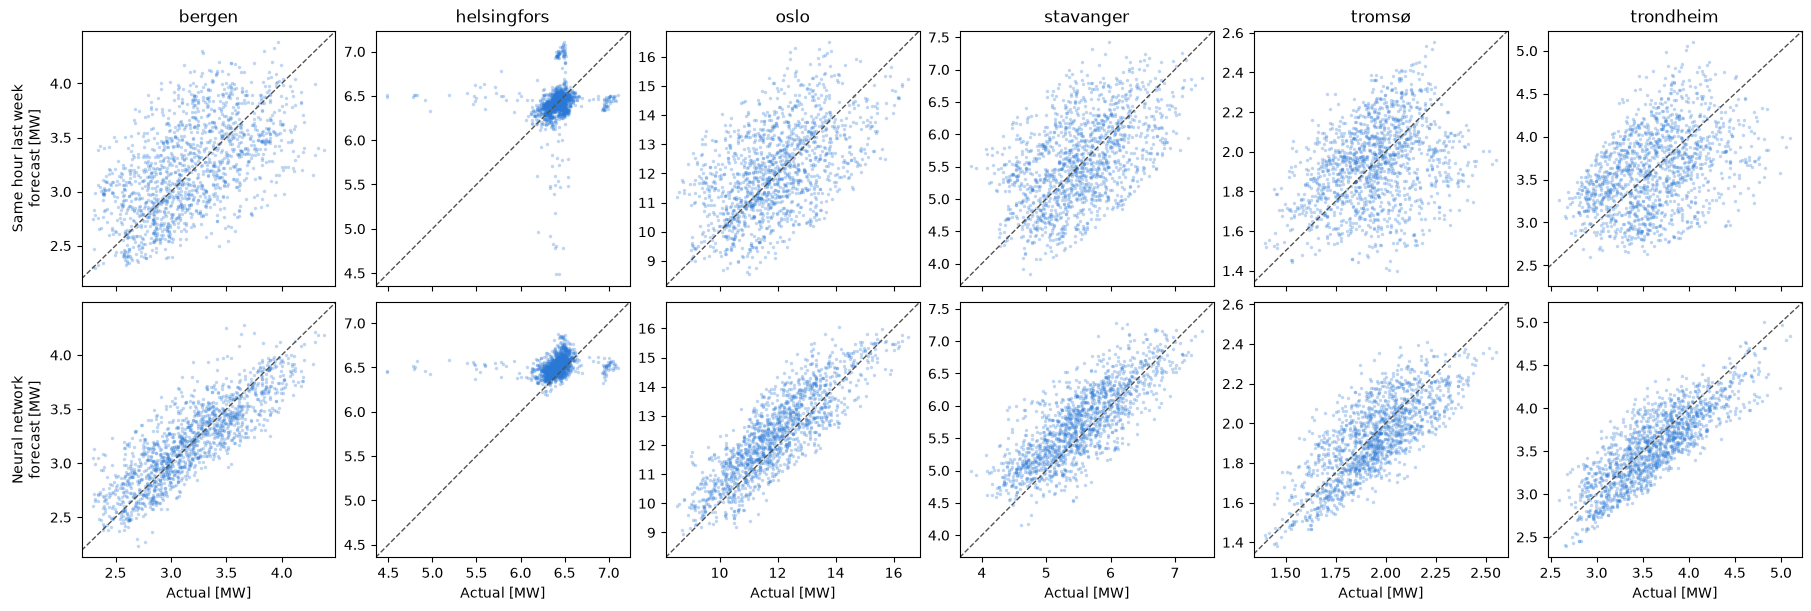

In [11]:
validator.plot_predicted_vs_actual_consumption()